# Case Study - Diamond Price Prediction

### Importing Libraries

In [108]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

### Loading the data

In [229]:
# data = pd.read_csv("diamonds.csv", index_col=0)       # index_col - This ignores the index column in csv file
data = pd.read_csv("diamonds.csv")                      # This will read the index column as well by Unnamed:0
data.head()

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


### Feature description:

1. **price:** Price in US dollars
2. **carat (0.2--5.01):** It is the diamond’s physical weight measured in metric carats. 
3. **cut (Fair, Good, Very Good, Premium, Ideal):** The more precise the diamond is cut, the more captivating the diamond is to the eye.
4. **color:** From J (worst) to D (best)
5. **clarity:** (I1 (worst), SI2, SI1, VS2, VS1, VVS2, VVS1, IF (best))
6. **Dimensions:**
   - x length in mm (0--10.74)
   - y width in mm (0--58.9)
   - z depth in mm (0--31.8)
7. **depath:** It is the percentage of diamond's total height to its avg width
8. **table:** It is the percentage of diamond's total width represented by its flat top face

In [230]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53940 non-null  int64  
 1   carat       53940 non-null  float64
 2   cut         53940 non-null  object 
 3   color       53940 non-null  object 
 4   clarity     53940 non-null  object 
 5   depth       53940 non-null  float64
 6   table       53940 non-null  float64
 7   price       53940 non-null  int64  
 8   x           53940 non-null  float64
 9   y           53940 non-null  float64
 10  z           53940 non-null  float64
dtypes: float64(6), int64(2), object(3)
memory usage: 4.5+ MB


In [231]:
data.shape

(53940, 11)

### Data Preprocessing:

1. Data cleaning
2. Identifying and removing outliers
3. Encoding categorical variables


##### Checking for duplicates

In [232]:
data.duplicated().sum()

0

##### Removing the unnamed column as it is not required

In [233]:
data.drop("Unnamed: 0", axis=1, inplace=True)

In [234]:
data.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


##### Outlier Detection

In [235]:
data.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


#### Observation:
Min value of "x", "y", "z" are zero, this indicates that there are faulty values in data that represents dimensionless or 2-dimensional diamonds.

In [236]:
# data[data['x']==0].index
# data[data['y']==0].index
# data[data['z']==0].index

In [237]:
print(len(data[data["x"]==0].index))
print(len(data[data["y"]==0].index))
print(len(data[data["z"]==0].index))

8
7
20


In [238]:
# Dropping dimensionless diamonds
data = data.drop(data[data["x"]==0].index)
data = data.drop(data[data["y"]==0].index)
data = data.drop(data[data["z"]==0].index)
data.shape

(53920, 10)

We have dropped 20 invalid data points by deleting the dimensionless (2-D or 1-D) diamonds.

In [239]:
data.describe()

,carat,depth,table,price,x,y,z
count,53920.000000,53920.000000,53920.000000,53920.000000,53920.000000,53920.000000,53920.000000
mean,0.797698,61.749514,57.456834,3930.993231,5.731627,5.734887,3.540046
std,0.473795,1.432331,2.234064,3987.280446,1.119423,1.140126,0.702530
min,0.200000,43.000000,43.000000,326.000000,3.730000,3.680000,1.070000
25%,0.400000,61.000000,56.000000,949.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5323.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [240]:
data.nlargest(10, 'carat')[['carat', 'depth', 'table', 'price', 'x', 'y', 'z']]

,carat,depth,table,price,x,y,z
27415,5.01,65.5,59.0,18018,10.74,10.54,6.98
27630,4.50,65.8,58.0,18531,10.23,10.16,6.72
27130,4.13,64.8,61.0,17329,10.00,9.85,6.43
25998,4.01,61.0,61.0,15223,10.14,10.10,6.17
25999,4.01,62.5,62.0,15223,10.02,9.94,6.24
26444,4.00,63.3,58.0,15984,10.01,9.94,6.31
26534,3.67,62.4,56.0,16193,9.86,9.81,6.13
23644,3.65,67.1,53.0,11668,9.53,9.48,6.38
27679,3.51,62.5,59.0,18701,9.66,9.63,6.03
24328,3.50,62.8,57.0,12587,9.65,9.59,6.03


In [241]:
data.nlargest(10, 'table')[['carat', 'depth', 'table', 'price', 'x', 'y', 'z']]

,carat,depth,table,price,x,y,z
24932,2.01,58.6,95.0,13387,8.32,8.31,4.87
50773,0.81,68.8,79.0,2301,5.26,5.20,3.58
51342,0.79,65.3,76.0,2362,5.52,5.13,3.35
49375,0.70,62.0,73.0,2100,5.65,5.54,3.47
51391,0.71,55.6,73.0,2368,6.01,5.96,3.33
52860,0.50,79.0,73.0,2579,5.21,5.18,4.09
52861,0.50,79.0,73.0,2579,5.21,5.18,4.09
44938,0.68,58.0,71.0,1633,5.85,5.70,3.35
314,0.76,59.0,70.0,2800,5.89,5.80,3.46
777,0.75,55.8,70.0,2859,6.09,5.98,3.37


In [242]:
data.nlargest(10, 'y')[['carat', 'depth', 'table', 'price', 'x', 'y', 'z']]

,carat,depth,table,price,x,y,z
24067,2.00,58.9,57.0,12210,8.09,58.90,8.06
49189,0.51,61.8,55.0,2075,5.15,31.80,5.12
27415,5.01,65.5,59.0,18018,10.74,10.54,6.98
27630,4.50,65.8,58.0,18531,10.23,10.16,6.72
25998,4.01,61.0,61.0,15223,10.14,10.10,6.17
25999,4.01,62.5,62.0,15223,10.02,9.94,6.24
26444,4.00,63.3,58.0,15984,10.01,9.94,6.31
27130,4.13,64.8,61.0,17329,10.00,9.85,6.43
26534,3.67,62.4,56.0,16193,9.86,9.81,6.13
27679,3.51,62.5,59.0,18701,9.66,9.63,6.03


In [243]:
data.nlargest(10, 'z')[['carat', 'depth', 'table', 'price', 'x', 'y', 'z']]

,carat,depth,table,price,x,y,z
48410,0.51,61.8,54.7,1970,5.12,5.15,31.80
24067,2.00,58.9,57.0,12210,8.09,58.90,8.06
27415,5.01,65.5,59.0,18018,10.74,10.54,6.98
27630,4.50,65.8,58.0,18531,10.23,10.16,6.72
27130,4.13,64.8,61.0,17329,10.00,9.85,6.43
23644,3.65,67.1,53.0,11668,9.53,9.48,6.38
26444,4.00,63.3,58.0,15984,10.01,9.94,6.31
26431,3.40,66.8,52.0,15964,9.42,9.34,6.27
25999,4.01,62.5,62.0,15223,10.02,9.94,6.24
25998,4.01,61.0,61.0,15223,10.14,10.10,6.17


For both y and z columns, 24067, 49189 & 48410 looks like as an outlier, so we can remove those rows.

In [244]:
data.drop(index=[24067, 49189, 48410], inplace=True)

### Dealing with the categorical variables

In [245]:
cat_cols = data.select_dtypes(include="object").columns
cat_cols

Index(['cut', 'color', 'clarity'], dtype='object')

Let us check for the number of unique values inside these columns

In [246]:
data['cut'].value_counts()

cut
Ideal        21547
Premium      13779
Very Good    12080
Good          4902
Fair          1609
Name: count, dtype: int64

In [247]:
data['color'].value_counts()

color
G    11284
E     9795
F     9538
H     8297
D     6774
I     5421
J     2808
Name: count, dtype: int64

In [248]:
data['clarity'].value_counts()

clarity
SI1     13063
VS2     12254
SI2      9184
VS1      8168
VVS2     5066
VVS1     3654
IF       1790
I1        738
Name: count, dtype: int64

- For cut column, we will use Ordinal Encoding
- For color and clarity column, we will use Label Encoding
- We use Label Encoding here, because only the worst and the best values are mentioned, the other specific details are not shown

We can even check for uniques in all categorical columns by creating plots for it.

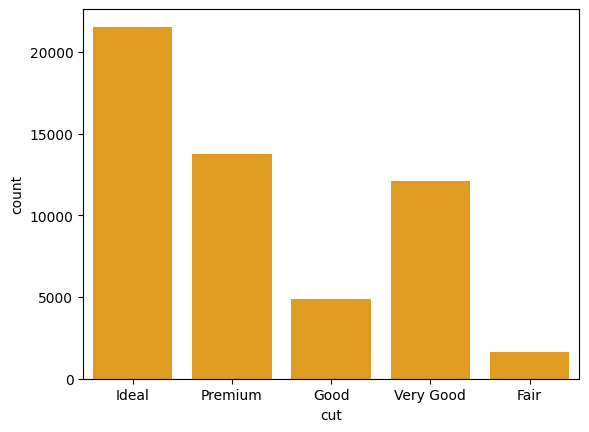

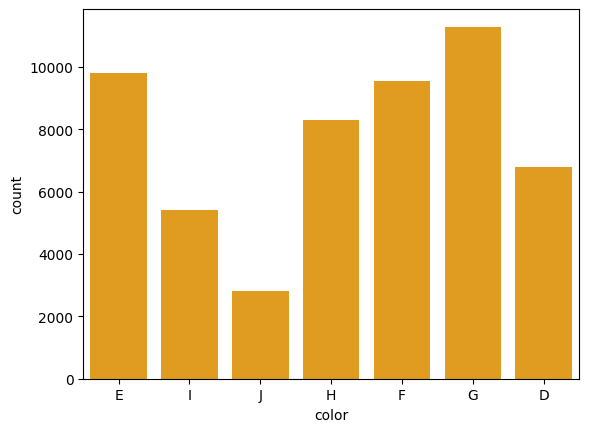

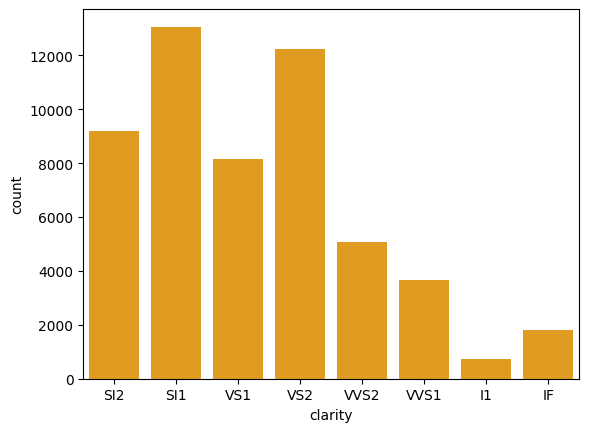

In [249]:
for c in ['cut', 'color', 'clarity']:
    sns.countplot(x=c, data=data, color='orange')
    plt.show()

**Ordinal Encoding**<br>
Converts the categories into numbers as per meaningful order.

In [251]:
data['cut'].values.reshape(-1,1)

array([['Ideal'],
       ['Premium'],
       ['Good'],
       ...,
       ['Very Good'],
       ['Premium'],
       ['Ideal']], dtype=object)

In [252]:
encoding_order = [['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']]

In [253]:
ordinal = OrdinalEncoder(categories=encoding_order)

In [254]:
data['cut'] = ordinal.fit_transform(data['cut'].values.reshape(-1,1))

In [255]:
data.head(3)

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,4.0,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,3.0,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,1.0,E,VS1,56.9,65.0,327,4.05,4.07,2.31


**Label Encoding**<br>
A label encoder assigns a unique integer to each distinct category in a dataset, ranging from 0 to n-1, where the assigned numbers do not necessarily represent any meaningful order.

In [257]:
label_encoder = LabelEncoder()

In [260]:
# color column:
data['color'] = label_encoder.fit_transform(data['color'])

In [261]:
# clarity column:
data['clarity'] = label_encoder.fit_transform(data['clarity'])

In [262]:
data.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,4.0,1,3,61.5,55.0,326,3.95,3.98,2.43
1,0.21,3.0,1,2,59.8,61.0,326,3.89,3.84,2.31
2,0.23,1.0,1,4,56.9,65.0,327,4.05,4.07,2.31
3,0.29,3.0,5,5,62.4,58.0,334,4.20,4.23,2.63
4,0.31,1.0,6,3,63.3,58.0,335,4.34,4.35,2.75


#### Verifying the relationships between all the columns

In [263]:
data.corr()

,carat,cut,color,clarity,depth,table,price,x,y,z
carat,1.000000,-0.134966,0.291326,-0.214217,0.028357,0.181646,0.921586,0.977778,0.976860,0.976478
cut,-0.134966,1.000000,-0.020516,0.122363,-0.218081,-0.433322,-0.053497,-0.126242,-0.125870,-0.152468
color,0.291326,-0.020516,1.000000,-0.027679,0.047407,0.026445,0.172394,0.270638,0.270447,0.274934
clarity,-0.214217,0.122363,-0.027679,1.000000,-0.053220,-0.088028,-0.071553,-0.225953,-0.223001,-0.229808
depth,0.028357,-0.218081,0.047407,-0.053220,1.000000,-0.295758,-0.010653,-0.024940,-0.028075,0.096741
table,0.181646,-0.433322,0.026445,-0.088028,-0.295758,1.000000,0.127241,0.196096,0.189942,0.155904
price,0.921586,-0.053497,0.172394,-0.071553,-0.010653,0.127241,1.000000,0.887221,0.888818,0.882107
x,0.977778,-0.126242,0.270638,-0.225953,-0.024940,0.196096,0.887221,1.000000,0.998657,0.991077
y,0.976860,-0.125870,0.270447,-0.223001,-0.028075,0.189942,0.888818,0.998657,1.000000,0.990730
z,0.976478,-0.152468,0.274934,-0.229808,0.096741,0.155904,0.882107,0.991077,0.990730,1.000000


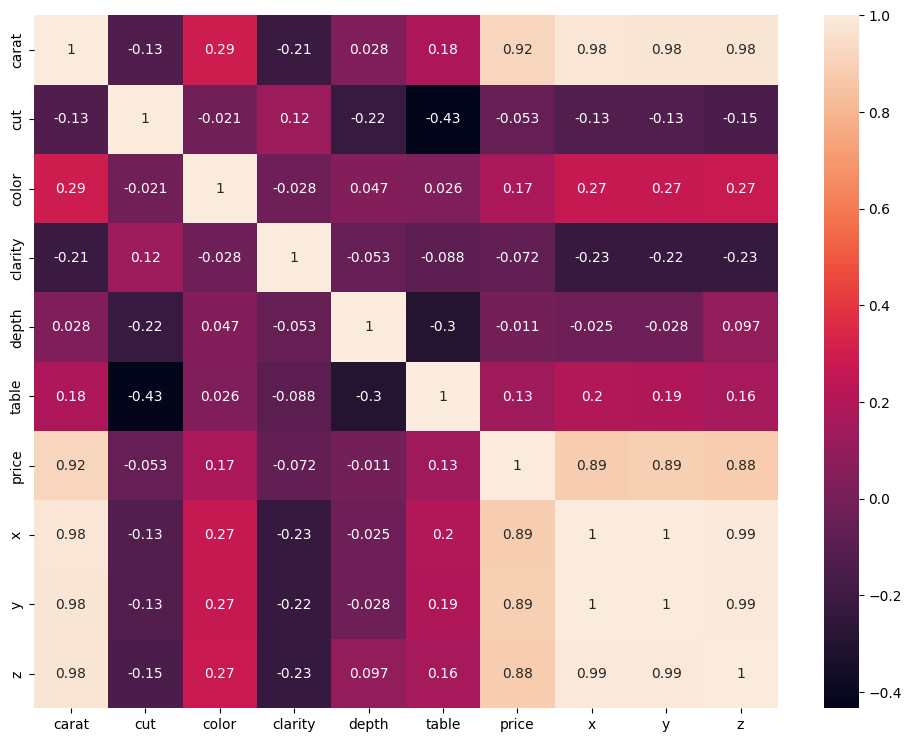

In [268]:
plt.figure(figsize=(12,9))
sns.heatmap(data.corr(), annot=True)
plt.show()

#### Data Splitting

In [269]:
X = data.drop("price", axis=1)
y = data["price"]

In [270]:
X.head(3)

,carat,cut,color,clarity,depth,table,x,y,z
0,0.23,4.0,1,3,61.5,55.0,3.95,3.98,2.43
1,0.21,3.0,1,2,59.8,61.0,3.89,3.84,2.31
2,0.23,1.0,1,4,56.9,65.0,4.05,4.07,2.31


In [271]:
y.head(3)

0    326
1    326
2    327
Name: price, dtype: int64

In [272]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

In [273]:
X_train.shape, y_train.shape

((40437, 9), (40437,))

In [274]:
X_test.shape, y_test.shape

((13480, 9), (13480,))

#### Scaling

In [275]:
scaling = StandardScaler()

In [276]:
X_train_scaled = scaling.fit_transform(X_train)
X_train_scaled

array([[-0.6909556 ,  0.9813297 , -0.93418892, ..., -0.66250142,
        -0.62397927, -0.63565689],
       [-0.88017111,  0.9813297 ,  1.41501568, ..., -0.98359597,
        -0.94736583, -0.95310922],
       [-0.20740486,  0.9813297 ,  0.24041338, ..., -0.09166665,
        -0.04906984,  0.01367743],
       ...,
       [-0.56481193, -1.70952465, -0.93418892, ..., -0.5554699 ,
        -0.51618375, -0.36149351],
       [-0.43866826, -1.70952465, -1.52149007, ..., -0.37708404,
        -0.42635415, -0.2460563 ],
       [-0.20740486, -0.8125732 , -1.52149007, ..., -0.09166665,
        -0.04906984,  0.01367743]])

In [277]:
X_test_scaled = scaling.transform(X_test)
X_test_scaled

array([[ 0.4653614 ,  0.9813297 , -1.52149007, ...,  0.6218768 ,
         0.660584  ,  0.66301174],
       [-0.83812322,  0.08437825, -0.93418892, ..., -0.84980657,
        -0.89346807, -0.95310922],
       [ 1.49553472, -1.70952465,  1.41501568, ...,  1.26406591,
         1.23549343,  1.44221292],
       ...,
       [ 0.42331351, -0.8125732 , -0.93418892, ...,  0.53268387,
         0.56177144,  0.66301174],
       [-1.00631479,  0.9813297 ,  0.24041338, ..., -1.17090113,
        -1.16295687, -1.18398364],
       [-1.09041057, -0.8125732 , -0.93418892, ..., -1.34928699,
        -1.33363311, -1.38599876]])

#### Model Building
Taking predictions using multiple models

In [278]:
model = LinearRegression()

In [279]:
model.fit(X_train_scaled, y_train)

LinearRegression()

In [284]:
train_score = model.score(X_train_scaled, y_train)
print(f'Score on Training Data: {round(train_score,2)}')

Score on Training Data: 0.89


In [285]:
test_score = model.score(X_test_scaled, y_test)
print(f'Score on Test Data: {round(test_score,2)}')

Score on Test Data: 0.89


##### Calculating Predictions

In [286]:
y_pred = model.predict(X_test_scaled)

In [287]:
y_pred

array([6085.4315629 ,  780.05375312, 8181.41229792, ..., 6541.05348221,
       -399.19818428, 1261.24830292])

In [288]:
y_test

15848     6340
33216      821
19627     8245
27103    17250
28939      684
         ...  
17339     6957
19608     8227
21008     9224
35889      918
29673      707
Name: price, Length: 13480, dtype: int64

Task: Compare the predictions of a few data points and try to plot the graph between them.

#### Comparing certain ML Algorithms

In [303]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [304]:
models = [LinearRegression(), DecisionTreeRegressor(max_depth=4), RandomForestRegressor(n_estimators=150, max_depth=5)]

In [305]:
for m in models:
    model = m
    model.fit(X_train_scaled, y_train)
    train_score = model.score(X_train_scaled, y_train)
    test_score = model.score(X_test_scaled, y_test)
    print(m)
    print(f'Score on Training Data: {round(train_score,2)}')
    print(f'Score on Test Data: {round(test_score,2)}')
    print('\n')

LinearRegression()
Score on Training Data: 0.89
Score on Test Data: 0.89


DecisionTreeRegressor(max_depth=4)
Score on Training Data: 0.91
Score on Test Data: 0.91


RandomForestRegressor(max_depth=5, n_estimators=150)
Score on Training Data: 0.94
Score on Test Data: 0.94




**Observation:**
- Linear Regression performs better than average on both training and test datasets.
- Decision Tree performs well on both datasets.
- But Random Forest gives the best performance on both datasets.